In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import torch
from chronos import Chronos2Pipeline

os.environ["CUDA_VISIBLE_DEVICES"] = "0"

print("🔄 Đang tải mô hình Chronos-2...")
pipeline = Chronos2Pipeline.from_pretrained(
    "amazon/chronos-2",
    device_map="cuda",
    torch_dtype=torch.bfloat16,
)
print("✅ Mô hình đã load thành công!")

🔄 Đang tải mô hình Chronos-2...


`torch_dtype` is deprecated! Use `dtype` instead!
`torch_dtype` is deprecated! Use `dtype` instead!


✅ Mô hình đã load thành công!


# 📈 Sliding Window Backtesting cho Chronos-2
Thay vì `Expanding Window` (lấy toàn bộ lịch sử lớn dần), **Sliding Window Backtesting** sử dụng một độ dài bối cảnh (Context Length) cố định. Do đó, cả điểm bắt đầu và điểm kết thúc của khối dữ liệu lịch sử đều bị "trượt" về phía trước theo thời gian.

Điều này rất hữu ích để kiểm tra khả năng "đánh hơi" xu hướng ngắn hạn của Chronos-2 thay vì phụ thuộc quá nhiều vào bộ nhớ lịch sử dài hạn xa xôi.

In [6]:
# ========== 1. LOAD & CHUẨN BỊ DỮ LIỆU ĐA MÃ ==========
df_final = pd.read_csv("../../data/processed/merged_data_final.csv")
df_final['timestamp'] = pd.to_datetime(df_final['timestamp'])

print("🔄 Đang Resample (B - Business Days) cho toàn bộ các mã cổ phiếu...")
dfs = []
for ticker_id, group in df_final.groupby('id'):
    g_resampled = group.set_index('timestamp').resample('B').ffill()
    g_resampled['id'] = ticker_id
    dfs.append(g_resampled.reset_index())
    
df_ticker = pd.concat(dfs, ignore_index=True)
print(f"✅ Đã hoàn thiện format Series cho {len(df_ticker)} dòng dữ liệu.")

🔄 Đang Resample (B - Business Days) cho toàn bộ các mã cổ phiếu...
✅ Đã hoàn thiện format Series cho 12884 dòng dữ liệu.


In [7]:
# ========== 2. ENGINE SLIDING WINDOW BACKTEST ==========
TARGET_COL = 'Close'
PREDICTION_LENGTH = 1   # Dự báo 1 ngày tương lai
CONTEXT_LENGTH = 180    # Cố định độ dài chuỗi cung cấp cho Model (Vd: Nhìn lại 180 ngày)
NUM_WINDOWS = 30        # Chạy backtest trên 30 ngày (tương ứng 30 cửa sổ trượt)
future_cols = ['is_derivative_exp', 'day_of_week', 'quarter', 'month']

all_metrics = []
all_forecasts = []

print(f"🔮 Bắt đầu Sliding Window Backtest:")
print(f"  • Độ nhìn lại (Context Length): {CONTEXT_LENGTH} ngày cố định")
print(f"  • Độ dự báo tương lai: {PREDICTION_LENGTH} ngày")
print(f"  • Số cửa sổ cắt: {NUM_WINDOWS} (Tương ứng list {NUM_WINDOWS} ngày cuối)")

for window in range(NUM_WINDOWS):
    offset = window * PREDICTION_LENGTH
    
    context_list = []
    future_list = []
    actual_list = []
    
    for ticker_id, group in df_ticker.groupby('id'):
        g_sorted = group.sort_values('timestamp')
        
        # Cắt mảng dạng SLIDING (Cả điểm bắt đầu và kết thúc đều lùi lại)
        g_context = g_sorted.iloc[-(PREDICTION_LENGTH + offset + CONTEXT_LENGTH) : -(PREDICTION_LENGTH + offset)]
        
        # Ground truth (Thực tế)
        if offset == 0:
            g_actual = g_sorted.iloc[-PREDICTION_LENGTH:]
        else:
            g_actual = g_sorted.iloc[-(PREDICTION_LENGTH + offset) : -offset]
            
        context_list.append(g_context)
        future_list.append(g_actual[['id', 'timestamp'] + future_cols])
        actual_list.append(g_actual)
        
    df_context_w = pd.concat(context_list, ignore_index=True)
    df_future_w = pd.concat(future_list, ignore_index=True)
    df_actual_w = pd.concat(actual_list, ignore_index=True)
    
    start_p = df_future_w['timestamp'].dt.date.min()
    end_p = df_future_w['timestamp'].dt.date.max()
    print(f"\n▶️ Đang chạy [Sliding Window {window + 1}/{NUM_WINDOWS}] - Dự báo cho {start_p} đến {end_p}")
    
    # Chạy dự báo (Zero-shot)
    forecast_w = pipeline.predict_df(
        df=df_context_w,
        future_df=df_future_w,
        prediction_length=PREDICTION_LENGTH,
        quantile_levels=[0.1, 0.5, 0.9],
        id_column="id",
        timestamp_column="timestamp",
        target=TARGET_COL,
        cross_learning=True,
        batch_size=100
    )
    
    # Gộp dự báo và thực tế để kiểm định
    merged_w = pd.merge(
        forecast_w[['id', 'timestamp', 'predictions']], 
        df_actual_w[['id', 'timestamp', 'Close']], 
        on=['id', 'timestamp']
    )
    merged_w['Window_ID'] = window + 1
    all_forecasts.append(merged_w)
    
    # Tính metrics
    for ticker, grp in merged_w.groupby('id'):
        y_pred = grp['predictions'].values
        y_true = grp['Close'].values
        
        mae = np.mean(np.abs(y_pred - y_true))
        rmse = np.sqrt(np.mean((y_pred - y_true) ** 2))
        mape = np.mean(np.abs((y_pred - y_true) / y_true)) * 100
        
        all_metrics.append({
            'Window': window + 1,
            'Mã CK': ticker,
            'MAE': mae,
            'RMSE': rmse,
            'MAPE': mape
        })

metrics_df = pd.DataFrame(all_metrics)
print("\n✅ Hoàn tất Sliding Window Backtest cho TẤT CẢ các mã!")

🔮 Bắt đầu Sliding Window Backtest:
  • Độ nhìn lại (Context Length): 180 ngày cố định
  • Độ dự báo tương lai: 1 ngày
  • Số cửa sổ cắt: 30 (Tương ứng list 30 ngày cuối)

▶️ Đang chạy [Sliding Window 1/30] - Dự báo cho 2025-12-31 đến 2025-12-31

▶️ Đang chạy [Sliding Window 2/30] - Dự báo cho 2025-12-30 đến 2025-12-30

▶️ Đang chạy [Sliding Window 3/30] - Dự báo cho 2025-12-29 đến 2025-12-29

▶️ Đang chạy [Sliding Window 4/30] - Dự báo cho 2025-12-26 đến 2025-12-26

▶️ Đang chạy [Sliding Window 5/30] - Dự báo cho 2025-12-25 đến 2025-12-25

▶️ Đang chạy [Sliding Window 6/30] - Dự báo cho 2025-12-24 đến 2025-12-24

▶️ Đang chạy [Sliding Window 7/30] - Dự báo cho 2025-12-23 đến 2025-12-23

▶️ Đang chạy [Sliding Window 8/30] - Dự báo cho 2025-12-22 đến 2025-12-22

▶️ Đang chạy [Sliding Window 9/30] - Dự báo cho 2025-12-19 đến 2025-12-19

▶️ Đang chạy [Sliding Window 10/30] - Dự báo cho 2025-12-18 đến 2025-12-18

▶️ Đang chạy [Sliding Window 11/30] - Dự báo cho 2025-12-17 đến 2025-12-17

▶️

In [8]:
# ========== 3. BẢNG TỔNG SẮP XẾP KẾT QUẢ ==========
avg_metrics = metrics_df.groupby('Mã CK').agg({
    'MAE': 'mean',
    'RMSE': 'mean',
    'MAPE': 'mean'
}).round(3).reset_index()

print("="*60)
print(f"🏆 KẾT QUẢ ĐÁNH GIÁ SLIDING WINDOW (Context Cố Định {CONTEXT_LENGTH} ngày)")
print("="*60)
display(avg_metrics)

print("\n=> 🌟 CỤC DIỆN TOÀN THỊ TRƯỜNG (Trung bình các Window):")
print(f"  • MAE  : {avg_metrics['MAE'].mean():.4f} VND")
print(f"  • RMSE : {avg_metrics['RMSE'].mean():.4f} VND")
print(f"  • MAPE : {avg_metrics['MAPE'].mean():.2f} %")

🏆 KẾT QUẢ ĐÁNH GIÁ SLIDING WINDOW (Context Cố Định 180 ngày)


,Mã CK,MAE,RMSE,MAPE
0,FPT,0.907,0.907,0.946
1,HPG,0.253,0.253,0.949
2,SSI,0.481,0.481,1.604
3,VCB,0.332,0.332,0.573
4,VHM,3.247,3.247,2.994
5,VNM,0.833,0.833,1.331



=> 🌟 CỤC DIỆN TOÀN THỊ TRƯỜNG (Trung bình các Window):
  • MAE  : 1.0088 VND
  • RMSE : 1.0088 VND
  • MAPE : 1.40 %


🎨 Đang xuất biểu đồ Sliding Window 30 ngày cuối...


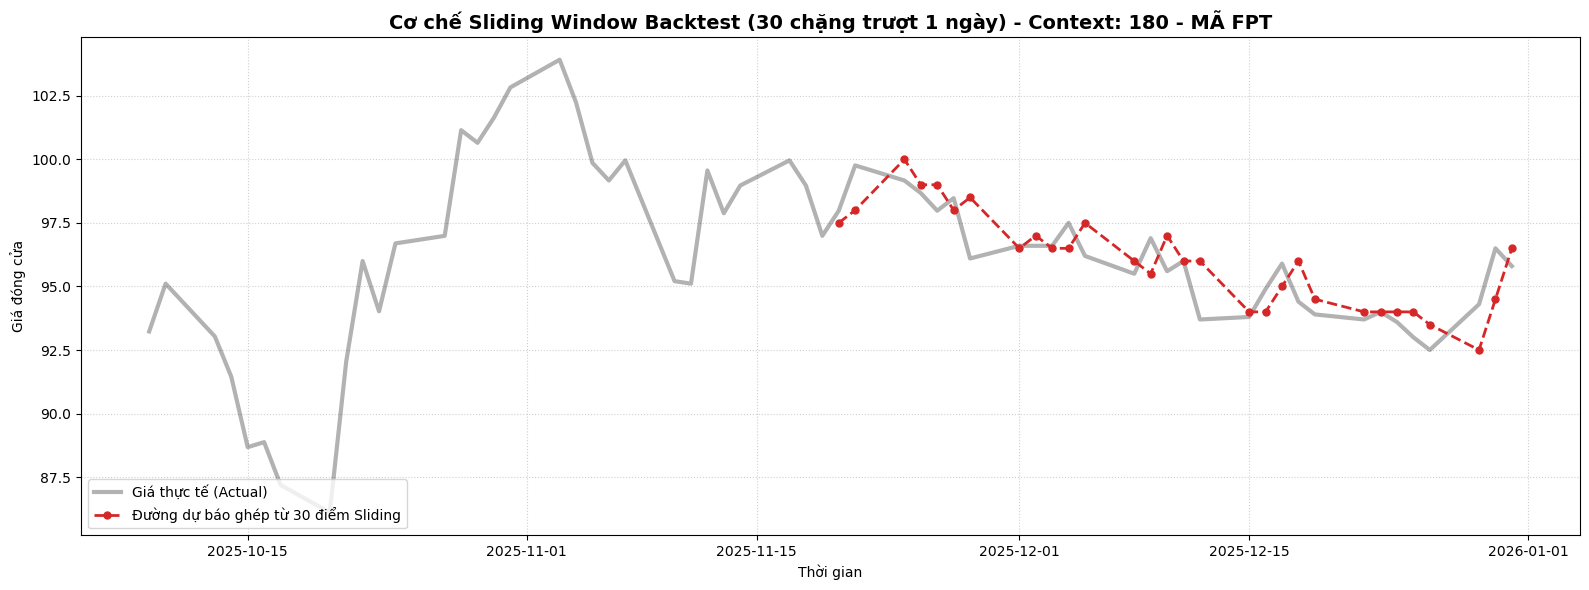

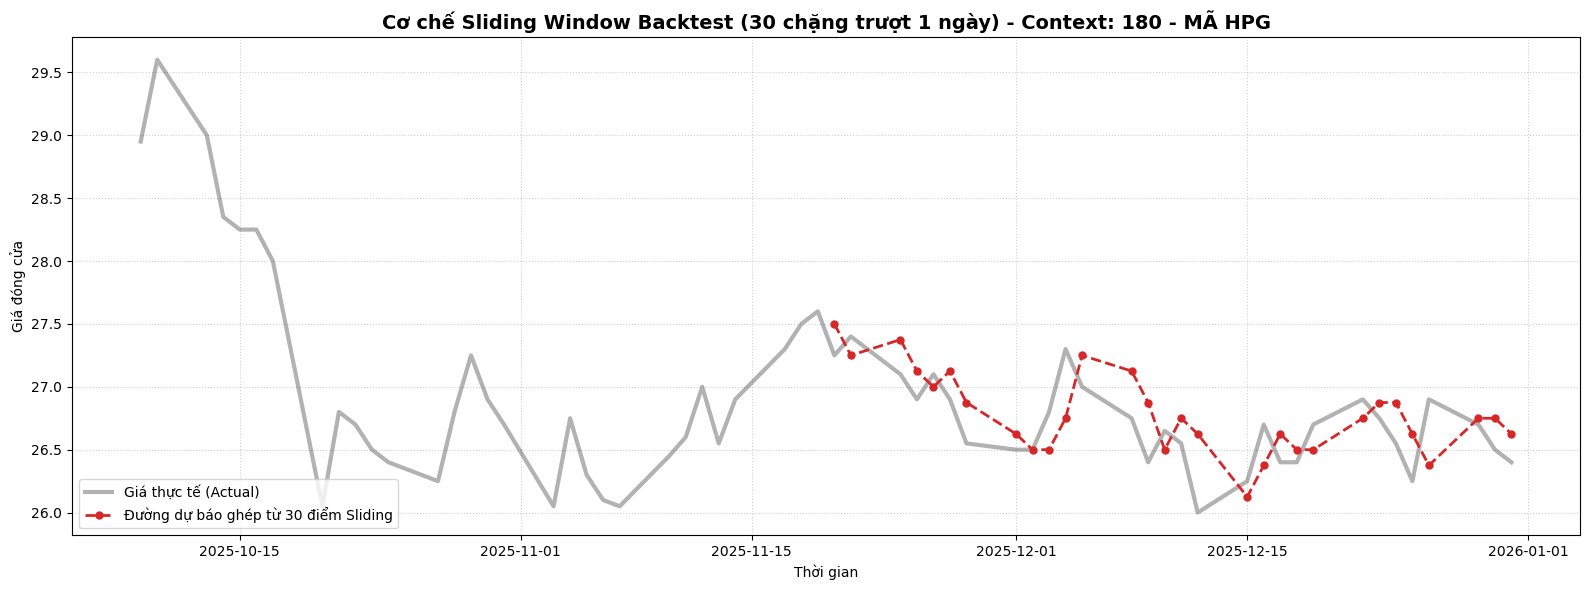

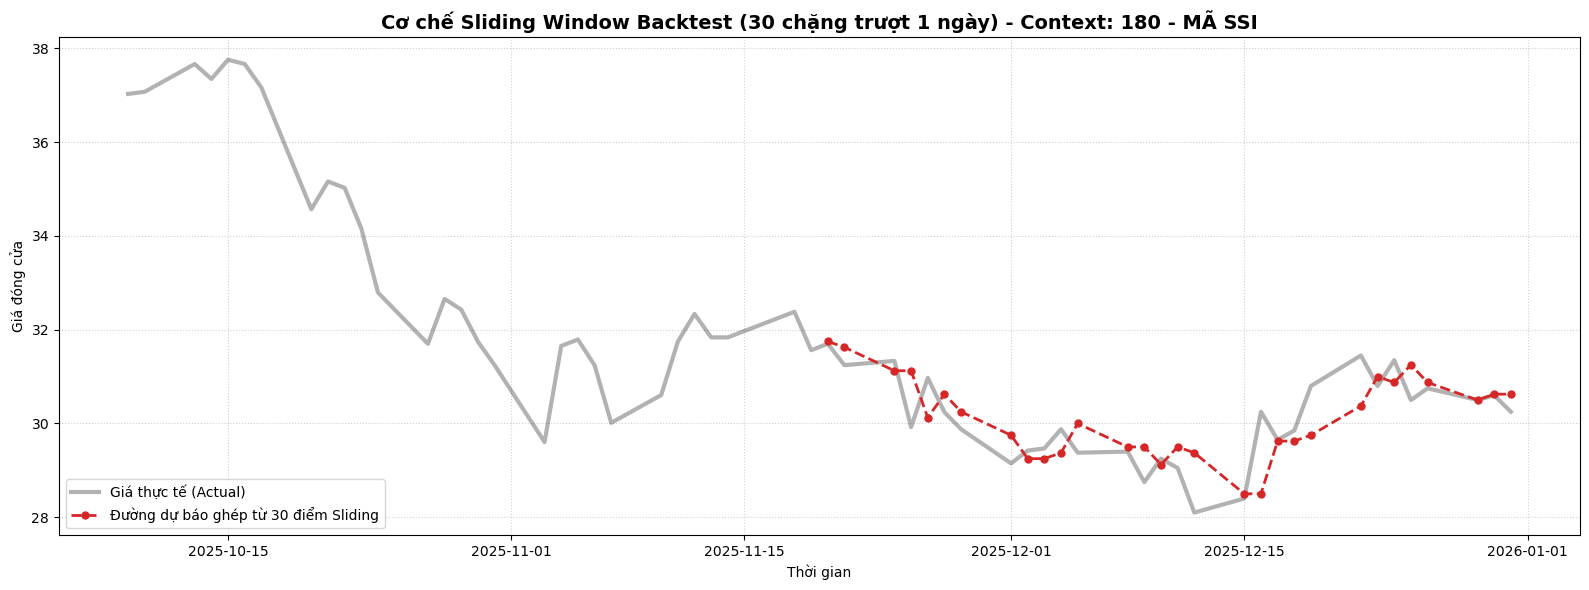

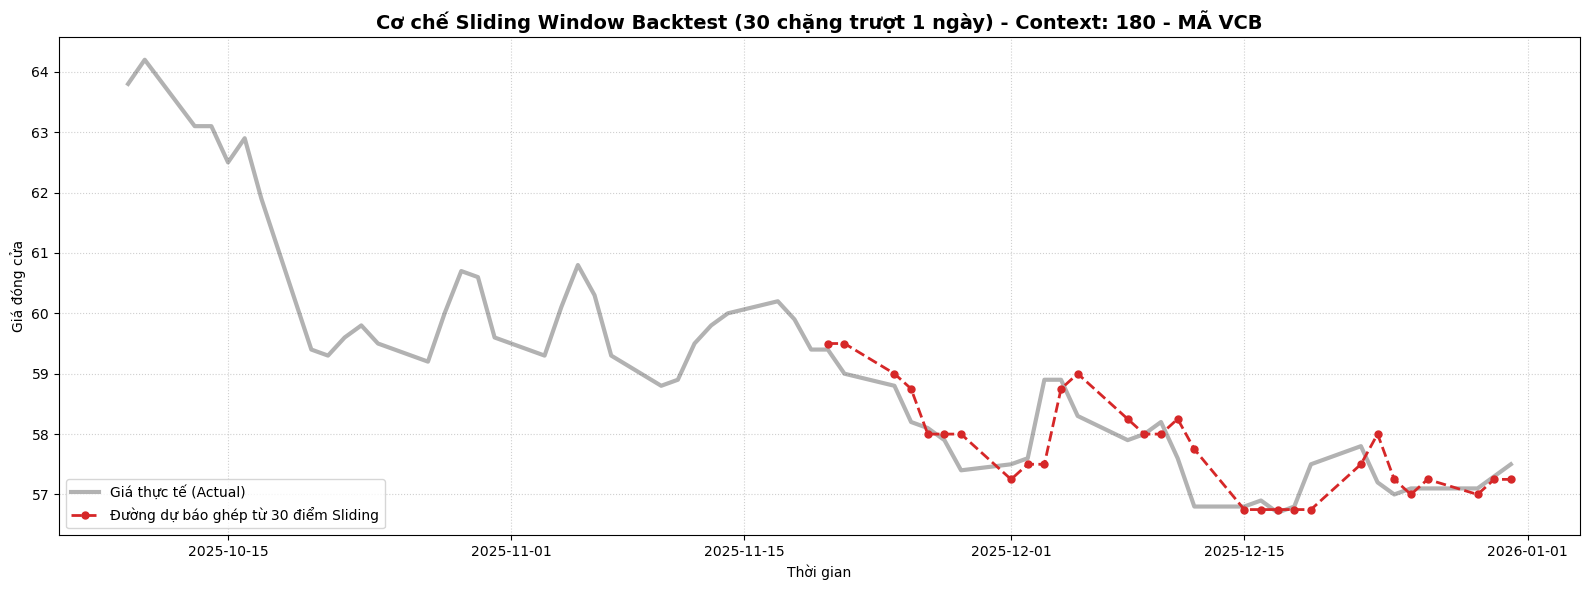

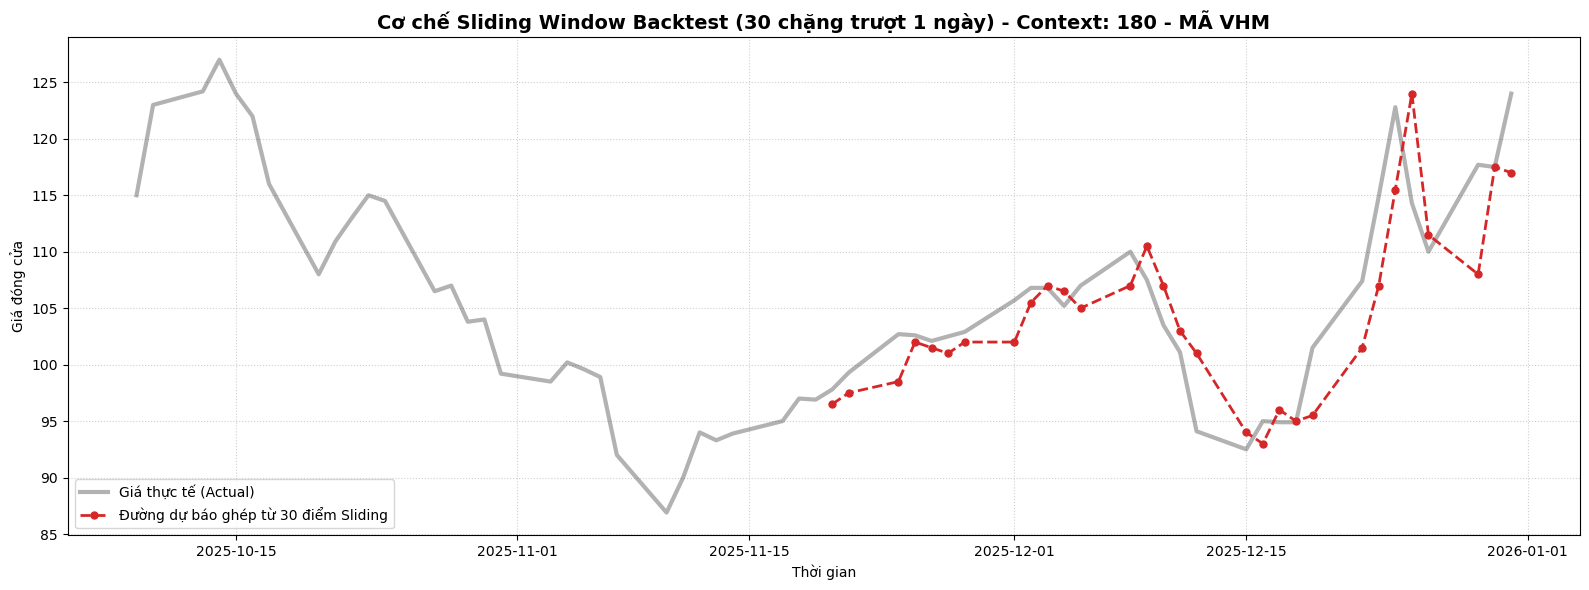

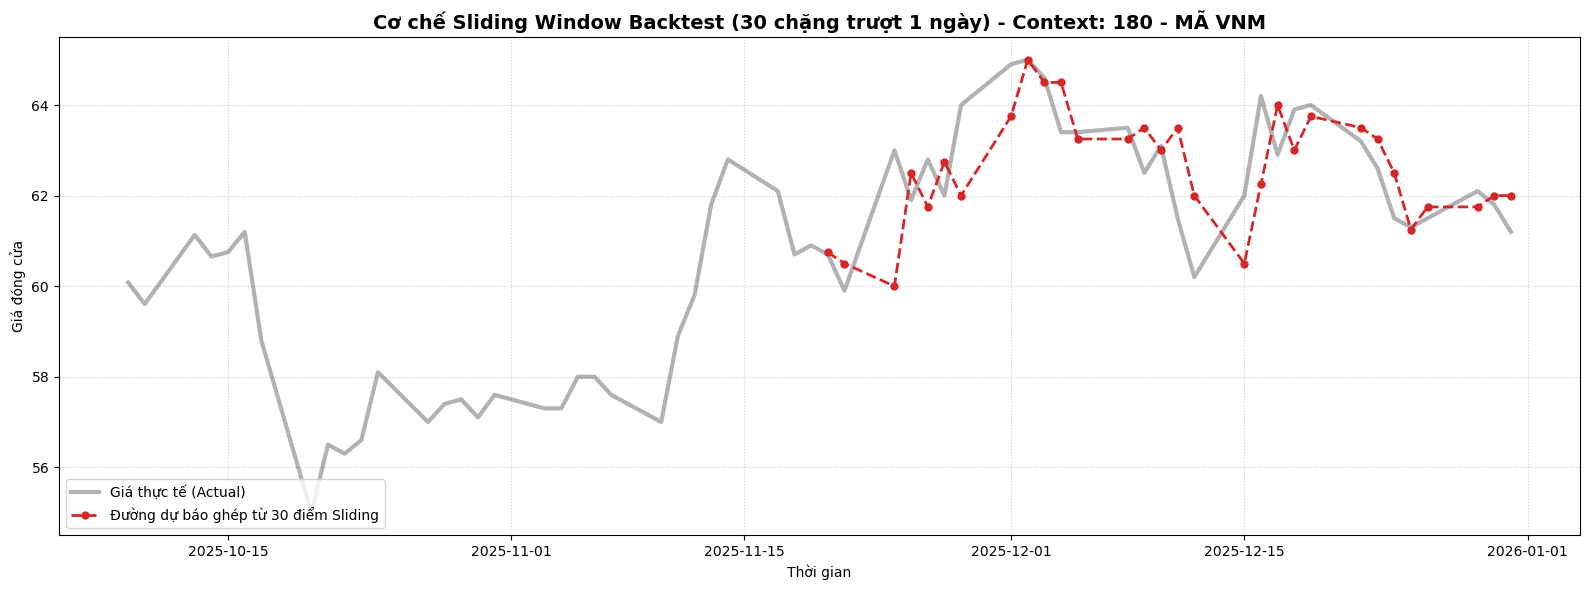

In [10]:
# ========== 4. TRỰC QUAN HÓA KẾT QUẢ SLIDING WINDOW ==========
import matplotlib.pyplot as plt

# Gộp tất cả các kết quả dự báo
if len(all_forecasts) > 0:
    df_all_forecasts = pd.concat(all_forecasts, ignore_index=True)

    def plot_sliding_forecasts(ticker):
        plt.figure(figsize=(16, 6))
        
        # Vẽ đường giá gốc nền
        days_to_show = PREDICTION_LENGTH * NUM_WINDOWS + 30 # Xo nhỏ biểu đồ lại, ta chỉ nhìn 30 ngày backtest + 30 ngày quá khứ
        df_hist = df_ticker[df_ticker['id'] == ticker].tail(days_to_show)
        plt.plot(df_hist['timestamp'], df_hist['Close'], label='Giá thực tế (Actual)', color='black', alpha=0.3, linewidth=3)
        
        # Vẽ các đoạn dự báo trượt
        df_pred = df_all_forecasts[df_all_forecasts['id'] == ticker].sort_values('timestamp')
        
        # Vì ta đang test 30 window, 1 block có 1 ngày nên sẽ gộp thành 1 đường liền mạch minh họa đi qua các ngày
        plt.plot(df_pred['timestamp'], df_pred['predictions'], label=f'Đường dự báo ghép từ {NUM_WINDOWS} điểm Sliding', 
                 marker='o', linestyle='--', color='#d62728', linewidth=2, markersize=5)

        plt.title(f'Cơ chế Sliding Window Backtest ({NUM_WINDOWS} chặng trượt 1 ngày) - Context: {CONTEXT_LENGTH} - MÃ {ticker}', fontsize=14, fontweight='bold')
        plt.xlabel('Thời gian')
        plt.ylabel('Giá đóng cửa')
        plt.legend(loc='lower left')
        plt.grid(True, linestyle=':', alpha=0.6)
        plt.tight_layout()
        plt.show()

    print("🎨 Đang xuất biểu đồ Sliding Window 30 ngày cuối...")
    tickers_to_show = df_all_forecasts['id'].unique()[:6]
    for t in tickers_to_show:
        plot_sliding_forecasts(t)
else:
    print("Chưa có dự báo để hiển thị!")